# Elsharnouby Data Analysis

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
Sales = pd.read_csv("data/Sales_Transactions.csv")
Inventory = pd.read_csv("data/Inventory_History.csv")
Production = pd.read_csv("data/Production_Orders.csv")
Customers = pd.read_csv("data/Customers.csv")
Business_Units = pd.read_csv("data/Business_Units.csv")
Case_Briefs = pd.read_csv("data/Case_Briefs.csv")
Customer_Service = pd.read_csv("data/Customer_Service.csv")
Data_Dictionary = pd.read_csv("data/Data_Dictionary.csv")
Group_Operations = pd.read_csv("data/Group_Operations.csv")
Locations = pd.read_csv("data/Locations.csv")
Machine_Downtime = pd.read_csv("data/Machine_Downtime.csv")
Marketing = pd.read_csv("data/Marketing.csv")
Materials = pd.read_csv("data/Materials.csv")
Printing_Batches = pd.read_csv("data/Printing_Batches.csv")
Product_BOM = pd.read_csv("data/Product_BOM.csv")
Product_Master = pd.read_csv("data/Product_Master.csv")
Purchase_Orders = pd.read_csv("data/Purchase_Orders.csv")
Quality = pd.read_csv("data/Quality.csv")
Suppliers = pd.read_csv("data/Suppliers.csv")
Web_Traffic_Daily = pd.read_csv("data/Web_Traffic_Daily.csv")

In [3]:
Data_list = [Sales, Inventory, Production, Customers, Business_Units, Case_Briefs, Customer_Service, Data_Dictionary, Group_Operations, Locations, Machine_Downtime, Marketing, Materials, Printing_Batches, Product_BOM, Product_Master, Purchase_Orders, Quality, Suppliers, Web_Traffic_Daily]

In [4]:
for df in Data_list:
    df.info()
    print("="*50)

<class 'pandas.DataFrame'>
RangeIndex: 180000 entries, 0 to 179999
Data columns (total 30 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   Row_ID                  180000 non-null  int64  
 1   Invoice_ID              180000 non-null  str    
 2   Order_Date              180000 non-null  str    
 3   Month_Key               180000 non-null  str    
 4   Location_ID             180000 non-null  str    
 5   Location_Name           180000 non-null  str    
 6   Channel                 180000 non-null  str    
 7   Customer_ID             180000 non-null  str    
 8   Customer_Type           180000 non-null  str    
 9   Customer_Governorate    180000 non-null  str    
 10  Product_ID              180000 non-null  str    
 11  SKU                     180000 non-null  str    
 12  Product_Name            180000 non-null  str    
 13  Product_Family          180000 non-null  str    
 14  Size                    180000 

## Sales Data

In [5]:
print(f"Shape: {Sales.shape}")

Sales.info()

print("\nMissing values:")
print(Sales.isnull().sum())

print("\nDuplicate rows:")
print(Sales.duplicated().sum())

Shape: (180000, 30)
<class 'pandas.DataFrame'>
RangeIndex: 180000 entries, 0 to 179999
Data columns (total 30 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   Row_ID                  180000 non-null  int64  
 1   Invoice_ID              180000 non-null  str    
 2   Order_Date              180000 non-null  str    
 3   Month_Key               180000 non-null  str    
 4   Location_ID             180000 non-null  str    
 5   Location_Name           180000 non-null  str    
 6   Channel                 180000 non-null  str    
 7   Customer_ID             180000 non-null  str    
 8   Customer_Type           180000 non-null  str    
 9   Customer_Governorate    180000 non-null  str    
 10  Product_ID              180000 non-null  str    
 11  SKU                     180000 non-null  str    
 12  Product_Name            180000 non-null  str    
 13  Product_Family          180000 non-null  str    
 14  Size       

In [6]:
Sales.head()

,Row_ID,Invoice_ID,Order_Date,Month_Key,Location_ID,Location_Name,Channel,Customer_ID,Customer_Type,Customer_Governorate,...,Estimated_COGS_EGP,Gross_Profit_EGP,Gross_Margin_Pct,Payment_Method,Returned,Return_Date,Return_Reason,Refund_Value_EGP,Quality_Related_Return,Data_Class
0,0,INV0000001,2024-05-11,2024-05,LOC002,LEO MODA Online Store,Online,C18976,Retail,Cairo,...,247.57,82.23,0.2493,Wallet,No,NaN,No return,0.0,No,Modeled training transaction anchored to publi...
1,1,INV0000002,2025-07-31,2025-07,LOC001,LEO MODA - Sidi Bishr Store,Retail,C22543,Retail,Alexandria,...,163.31,67.89,0.2936,Card,No,NaN,No return,0.0,No,Modeled training transaction anchored to publi...
2,2,INV0000003,2026-05-23,2026-05,LOC003,El-Sharnouby Wholesale Desk,Wholesale,C13351,Wholesale,Alexandria,...,4301.71,512.69,0.1065,Cash,No,NaN,No return,0.0,No,Modeled training transaction anchored to publi...
3,3,INV0000004,2024-06-05,2024-06,LOC003,El-Sharnouby Wholesale Desk,Wholesale,C21377,Wholesale,Dakahlia,...,10451.13,907.59,0.0799,Bank Transfer,No,NaN,No return,0.0,No,Modeled training transaction anchored to publi...
4,4,INV0000005,2025-12-28,2025-12,LOC001,LEO MODA - Sidi Bishr Store,Retail,C21499,Retail,Alexandria,...,186.16,53.04,0.2217,Cash,No,NaN,No return,0.0,No,Modeled training transaction anchored to publi...


In [7]:
Sales.describe()

,Row_ID,Quantity,List_Price_EGP,Discount_Pct,Gross_Sales_EGP,Net_Sales_EGP,Estimated_COGS_EGP,Gross_Profit_EGP,Gross_Margin_Pct,Refund_Value_EGP
count,180000.000000,180000.000000,180000.000000,180000.000000,180000.000000,180000.000000,180000.000000,180000.000000,180000.000000,180000.000000
mean,89999.500000,9.225494,360.764444,0.138623,3333.844783,2340.768764,1980.278265,360.490499,0.291653,52.372253
std,51961.668564,14.739688,78.323725,0.129883,5501.195186,3669.395593,3270.571060,566.158340,0.130789,558.590584
min,0.000000,1.000000,289.000000,0.000000,289.000000,216.750000,155.110000,-1903.790000,-0.141700,0.000000
25%,44999.750000,1.000000,299.000000,0.000000,348.000000,310.400000,200.020000,107.720000,0.202400,0.000000
50%,89999.500000,1.000000,348.000000,0.100000,549.000000,494.100000,316.820000,151.280000,0.323800,0.000000
75%,134999.250000,12.000000,388.000000,0.280000,3960.000000,2692.800000,2380.150000,337.440000,0.389700,0.000000
max,179999.000000,60.000000,549.000000,0.380000,32940.000000,23716.800000,21628.410000,6708.040000,0.510000,23716.800000


## Inventory Data

In [8]:
print(f"Shape: {Inventory.shape}")

Inventory.info()

print("\nMissing values:")
print(Inventory.isnull().sum())

print("\nDuplicate rows:")
print(Inventory.duplicated().sum())

Shape: (6372, 19)
<class 'pandas.DataFrame'>
RangeIndex: 6372 entries, 0 to 6371
Data columns (total 19 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Snapshot_Month           6372 non-null   str    
 1   Location_ID              6372 non-null   str    
 2   Location_Name            6372 non-null   str    
 3   Product_ID               6372 non-null   str    
 4   SKU                      6372 non-null   str    
 5   Product_Name             6372 non-null   str    
 6   Opening_Stock            6372 non-null   int64  
 7   Received_Qty             6372 non-null   int64  
 8   Sold_Qty                 6372 non-null   int64  
 9   Returned_Qty             6372 non-null   int64  
 10  Damaged_Qty              6372 non-null   int64  
 11  Closing_Stock            6372 non-null   int64  
 12  Avg_Daily_Sales_90D      6372 non-null   float64
 13  Safety_Stock_Units       6372 non-null   int64  
 14  Reorder_Point_Uni

In [9]:
Inventory.head()

,Snapshot_Month,Location_ID,Location_Name,Product_ID,SKU,Product_Name,Opening_Stock,Received_Qty,Sold_Qty,Returned_Qty,Damaged_Qty,Closing_Stock,Avg_Daily_Sales_90D,Safety_Stock_Units,Reorder_Point_Units,Supplier_Lead_Time_Days,Days_of_Cover,Stockout_Days_In_Month,Data_Class
0,2023-10-01,LOC001,LEO MODA - Sidi Bishr Store,P001,26115-8,Summer children's girls-Happy,176,39,42,3,0,176,1.38,5,12,5,127.5,0,Modeled inventory history - no forecast column...
1,2023-11-01,LOC001,LEO MODA - Sidi Bishr Store,P001,26115-8,Summer children's girls-Happy,176,65,62,4,1,182,1.71,23,59,21,106.4,0,Modeled inventory history - no forecast column...
2,2023-12-01,LOC001,LEO MODA - Sidi Bishr Store,P001,26115-8,Summer children's girls-Happy,182,54,61,1,1,175,1.81,25,63,21,96.7,0,Modeled inventory history - no forecast column...
3,2024-01-01,LOC001,LEO MODA - Sidi Bishr Store,P001,26115-8,Summer children's girls-Happy,175,35,42,1,0,169,1.81,12,30,10,93.4,0,Modeled inventory history - no forecast column...
4,2024-02-01,LOC001,LEO MODA - Sidi Bishr Store,P001,26115-8,Summer children's girls-Happy,169,28,31,1,0,167,1.47,7,17,7,113.6,0,Modeled inventory history - no forecast column...


In [10]:
Inventory.describe()

,Opening_Stock,Received_Qty,Sold_Qty,Returned_Qty,Damaged_Qty,Closing_Stock,Avg_Daily_Sales_90D,Safety_Stock_Units,Reorder_Point_Units,Supplier_Lead_Time_Days,Days_of_Cover,Stockout_Days_In_Month
count,6372.000000,6372.000000,6372.000000,6372.000000,6372.000000,6372.000000,6372.000000,6372.000000,6372.000000,6372.000000,6372.000000,6372.000000
mean,358.662586,257.446014,260.607188,5.843220,0.954175,362.854991,8.518817,63.247018,159.731481,11.387006,335.284401,0.187853
std,493.797621,451.562006,465.679225,14.663688,1.795573,510.997804,14.562623,122.996414,312.608413,5.702063,1147.483763,1.312087
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.040000,5.000000,5.000000,5.000000,0.000000,0.000000
25%,135.000000,25.000000,23.000000,0.000000,0.000000,133.000000,0.817500,5.000000,13.000000,7.000000,33.700000,0.000000
50%,222.000000,64.000000,56.000000,1.000000,0.000000,222.000000,1.840000,13.000000,33.000000,10.000000,96.150000,0.000000
75%,341.000000,264.250000,264.000000,4.000000,1.000000,339.250000,9.870000,61.000000,154.250000,14.000000,223.800000,0.000000
max,3696.000000,4011.000000,4500.000000,186.000000,18.000000,3789.000000,133.220000,1467.000000,3724.000000,21.000000,21175.000000,13.000000


## Production Data

In [11]:
print(f"Shape: {Production.shape}")

Production.info()

print("\nMissing values:")
print(Production.isnull().sum())

print("\nDuplicate rows:")
print(Production.duplicated().sum())

Shape: (2500, 16)
<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Production_Order_ID  2500 non-null   str    
 1   Product_ID           2500 non-null   str    
 2   Product_Name         2500 non-null   str    
 3   Start_Date           2500 non-null   str    
 4   Due_Date             2500 non-null   str    
 5   Completion_Date      2500 non-null   str    
 6   Planned_Qty          2500 non-null   int64  
 7   Produced_Qty         2500 non-null   int64  
 8   Good_Qty             2500 non-null   int64  
 9   Rejected_Qty         2500 non-null   int64  
 10  Line_ID              2500 non-null   str    
 11  Efficiency_Pct       2500 non-null   float64
 12  Delay_Days           2500 non-null   int64  
 13  Primary_Bottleneck   407 non-null    str    
 14  Overtime_Hours       2500 non-null   float64
 15  Data_Class           2500 non-n

In [12]:
Production.head()

,Production_Order_ID,Product_ID,Product_Name,Start_Date,Due_Date,Completion_Date,Planned_Qty,Produced_Qty,Good_Qty,Rejected_Qty,Line_ID,Efficiency_Pct,Delay_Days,Primary_Bottleneck,Overtime_Hours,Data_Class
0,PO00001,P035,Girls' sweatshirt-Fuchsia,2025-11-11,2025-11-22,2025-11-22,1228,1140,1124,16,LINE-05,81.1,0,NaN,4.5,Modeled factory production order
1,PO00002,P055,Scooby-Doo - بيجامة حريمي صيفي2024,2025-09-01,2025-09-19,2025-09-19,1215,1215,1185,30,LINE-04,89.7,0,NaN,0.5,Modeled factory production order
2,PO00003,P001,Summer children's girls-Happy,2025-03-22,2025-04-08,2025-04-15,613,580,562,18,LINE-04,86.5,7,Finishing,14.7,Modeled factory production order
3,PO00004,P001,Summer children's girls-Happy,2024-05-06,2024-05-22,2024-05-22,4533,3640,3557,83,LINE-03,72.2,0,NaN,3.6,Modeled factory production order
4,PO00005,P045,Girls' autumn pajamas-Stitch,2025-08-08,2025-08-22,2025-08-22,987,756,746,10,LINE-02,72.5,0,NaN,13.6,Modeled factory production order


In [13]:
Production.describe()

,Planned_Qty,Produced_Qty,Good_Qty,Rejected_Qty,Efficiency_Pct,Delay_Days,Overtime_Hours
count,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000
mean,2758.990400,2507.088000,2444.592000,62.496000,82.209120,0.892800,7.050360
std,1418.619949,1313.183698,1280.997255,46.340584,8.597128,2.421994,6.105137
min,300.000000,228.000000,224.000000,1.000000,48.300000,0.000000,0.000000
25%,1512.500000,1365.250000,1331.000000,25.000000,76.500000,0.000000,1.600000
50%,2749.000000,2484.500000,2423.500000,52.000000,82.900000,0.000000,6.100000
75%,4028.250000,3586.000000,3478.000000,90.000000,88.400000,0.000000,11.000000
max,5200.000000,5186.000000,5129.000000,265.000000,97.000000,16.000000,33.100000


## Customers Data

In [14]:
print(f"Shape: {Customers.shape}")

Customers.info()

print("\nMissing values:")
print(Customers.isnull().sum())

print("\nDuplicate rows:")
print(Customers.duplicated().sum())

Shape: (30000, 9)
<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Customer_ID          30000 non-null  str  
 1   Customer_Type        30000 non-null  str  
 2   Governorate          30000 non-null  str  
 3   Age_Band             30000 non-null  str  
 4   Gender               30000 non-null  str  
 5   Join_Date            30000 non-null  str  
 6   Acquisition_Channel  30000 non-null  str  
 7   Consent_Status       30000 non-null  str  
 8   Data_Class           30000 non-null  str  
dtypes: str(9)
memory usage: 5.7 MB

Missing values:
Customer_ID            0
Customer_Type          0
Governorate            0
Age_Band               0
Gender                 0
Join_Date              0
Acquisition_Channel    0
Consent_Status         0
Data_Class             0
dtype: int64

Duplicate rows:
0


In [15]:
Customers.head()

,Customer_ID,Customer_Type,Governorate,Age_Band,Gender,Join_Date,Acquisition_Channel,Consent_Status,Data_Class
0,C00001,Retail,Dakahlia,45-54,Male,2026-02-22,Organic Social,Not opted-in,Modeled/anonymized training customer - not act...
1,C00002,Retail,Beheira,35-44,Male,2024-09-30,Direct / WhatsApp,Opted-in,Modeled/anonymized training customer - not act...
2,C00003,Retail,Dakahlia,25-34,Female,2025-06-27,Organic Social,Opted-in,Modeled/anonymized training customer - not act...
3,C00004,Wholesale,Port Said,Business,Business,2024-09-27,Wholesale Sales,Opted-in,Modeled/anonymized training customer - not act...
4,C00005,Retail,Gharbia,55+,Female,2025-02-07,Paid Social,Not opted-in,Modeled/anonymized training customer - not act...


In [16]:
Customers.describe()

,Customer_ID,Customer_Type,Governorate,Age_Band,Gender,Join_Date,Acquisition_Channel,Consent_Status,Data_Class
count,30000,30000,30000,30000,30000,30000,30000,30000,30000
unique,30000,2,13,6,4,1096,7,2,1
top,C00001,Retail,Alexandria,25-34,Female,2026-02-19,Direct / WhatsApp,Opted-in,Modeled/anonymized training customer - not act...
freq,1,28349,8415,10705,18931,45,6316,19187,30000


### Convert Date Columns

In [17]:
Sales['Order_Date'] = pd.to_datetime(Sales['Order_Date'])
Sales['Month_Key'] = pd.to_datetime(Sales['Month_Key'])
Sales['Return_Date'] = pd.to_datetime(Sales['Return_Date'])

In [18]:
Inventory['Snapshot_Month'] = pd.to_datetime(Inventory['Snapshot_Month'])

In [19]:
Production['Start_Date'] = pd.to_datetime(Production['Start_Date'])
Production['Due_Date'] = pd.to_datetime(Production['Due_Date'])
Production['Completion_Date'] = pd.to_datetime(Production['Completion_Date'])

In [20]:
Customers['Join_Date'] = pd.to_datetime(Customers['Join_Date'])

In [21]:
Customer_Service['Open_Date'] = pd.to_datetime(Customer_Service['Open_Date'])

In [22]:
Group_Operations['Month'] = pd.to_datetime(Group_Operations['Month'])

In [23]:
Machine_Downtime['Data'] = pd.to_datetime(Machine_Downtime['Date'])

In [24]:
Marketing['Start_Date'] = pd.to_datetime(Marketing['Start_Date'])

In [25]:
Printing_Batches['Print_Date'] = pd.to_datetime(Printing_Batches['Print_Date'])

In [26]:
Purchase_Orders['Order_Date'] = pd.to_datetime(Purchase_Orders['Order_Date'])

In [27]:
Web_Traffic_Daily['Date'] = pd.to_datetime(Web_Traffic_Daily['Date'])

### monthly sales

In [28]:
monthly_sales = (
    Sales.groupby("Month_Key")
    .agg(
        Total_Units=("Quantity", "sum"),
        Gross_Sales=("Gross_Sales_EGP", "sum"),
        Net_Sales=("Net_Sales_EGP", "sum"),
        Gross_Profit=("Gross_Profit_EGP", "sum"),
        Number_of_Invoices=("Invoice_ID", "nunique")
        
    )
    .reset_index()
)

In [29]:
monthly_sales

,Month_Key,Total_Units,Gross_Sales,Net_Sales,Gross_Profit,Number_of_Invoices
0,2023-10-01,36484,13766065,9663345.29,1558433.72,3753
1,2023-11-01,40007,15357356,10771256.46,1712293.37,4274
2,2023-12-01,45928,17511126,12277328.47,1924678.09,4783
3,2024-01-01,34495,13089177,9172864.77,1461991.42,3719
4,2024-02-01,32923,12575755,8800097.31,1383406.49,3349
5,2024-03-01,40500,14621476,10277634.17,1605080.00,4251
6,2024-04-01,46938,16395096,11486993.44,1685023.12,4789
7,2024-05-01,46803,16260687,11421809.19,1678468.53,5143
8,2024-06-01,48357,16845455,11792982.05,1740982.49,5073
9,2024-07-01,52210,18159990,12719754.24,1872945.74,5439


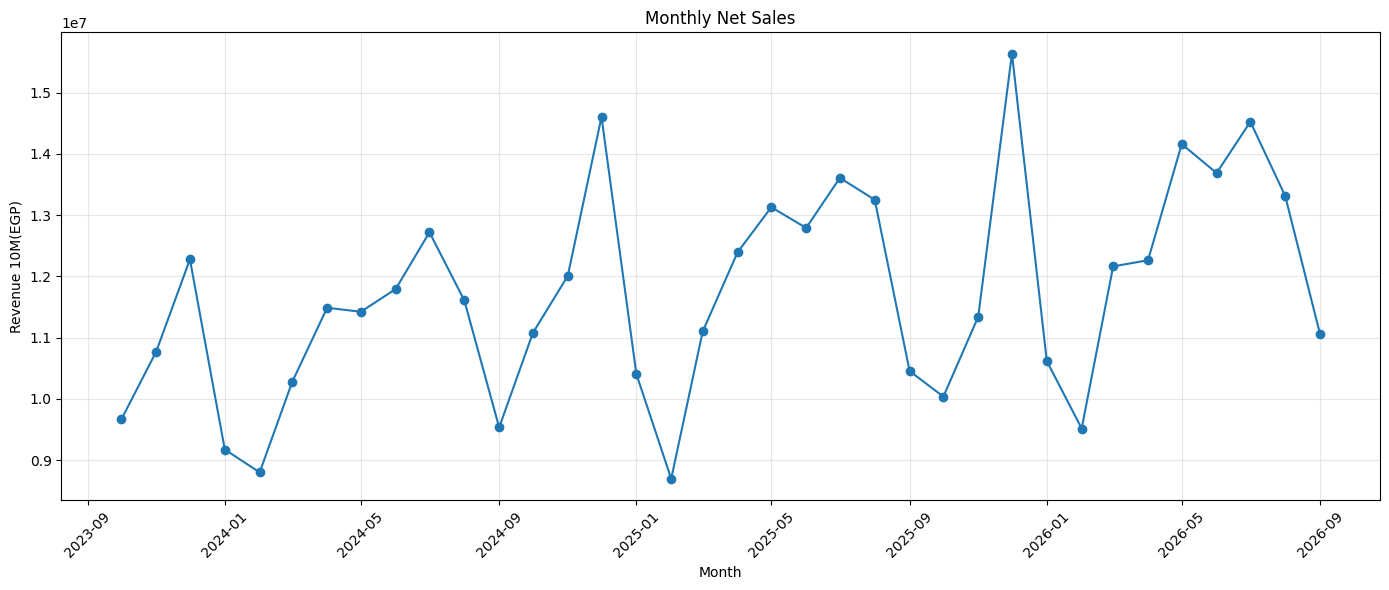

In [30]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["Month_Key"],
    monthly_sales["Net_Sales"],
    marker="o"
)

plt.title("Monthly Net Sales")
plt.xlabel("Month")
plt.ylabel("Revenue 10M(EGP)")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

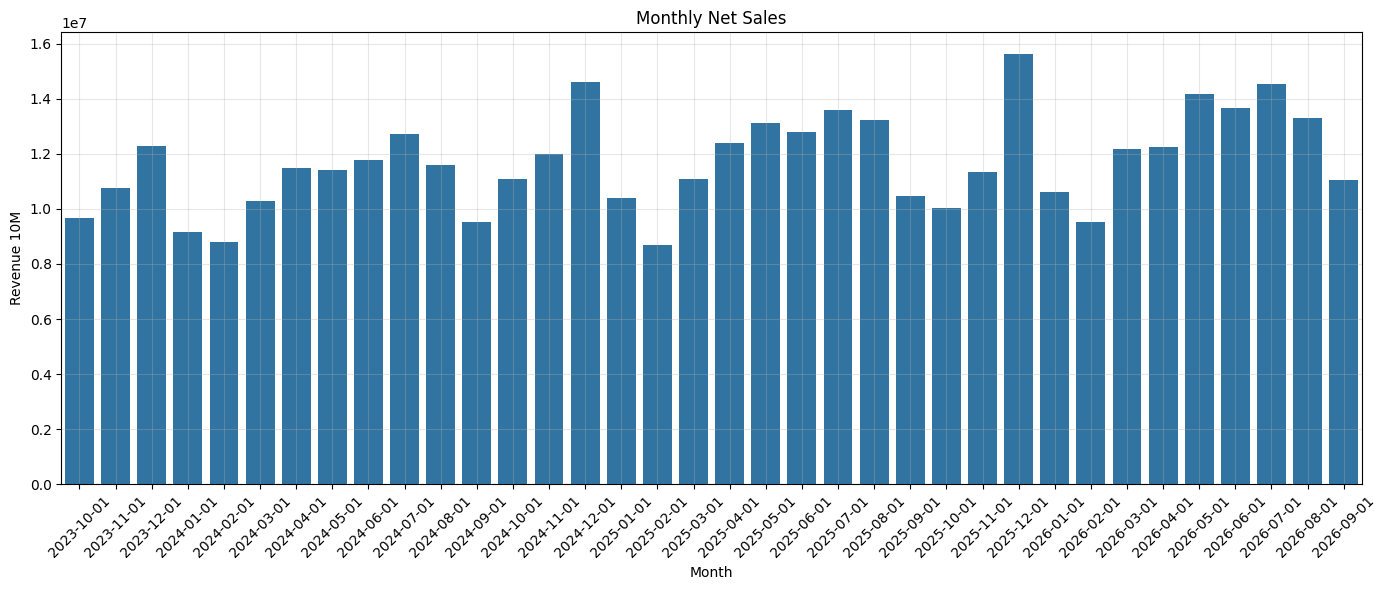

In [31]:
plt.figure(figsize=(14, 6))

sns.barplot(
    x=monthly_sales["Month_Key"],
    y=monthly_sales["Net_Sales"],
)

plt.title("Monthly Net Sales")
plt.xlabel("Month")
plt.ylabel("Revenue 10M")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

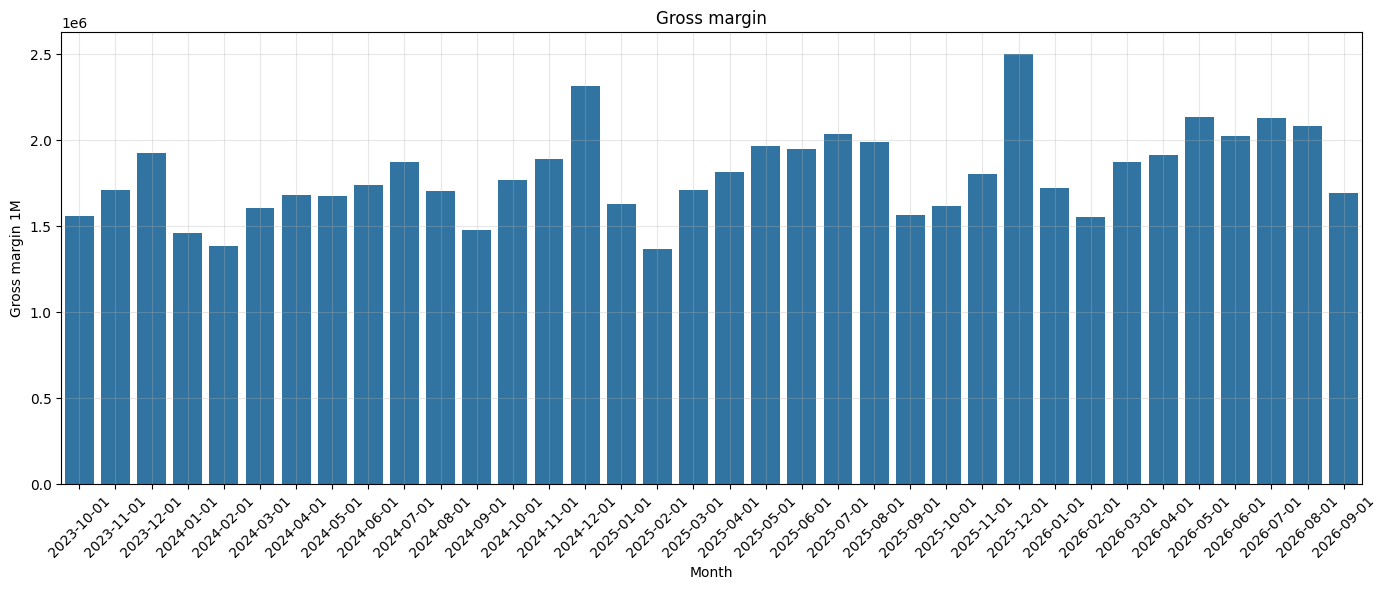

In [41]:
plt.figure(figsize=(14, 6))

sns.barplot(
    x=monthly_sales["Month_Key"],
    y=monthly_sales["Gross_Profit"],
)

plt.title("Gross margin")
plt.xlabel("Month")
plt.ylabel("Gross margin 1M")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

In [32]:
monthly_sales[["Net_Sales"]].sum()

Net_Sales    4.213384e+08
dtype: float64

In [35]:
customer_type_sales = (
    Sales.groupby("Channel")
    .agg(
        Total_Units=("Quantity", "sum"),
        Gross_Sales=("Gross_Sales_EGP", "sum"),
        Net_Sales=("Net_Sales_EGP", "sum"),
        Gross_Profit=("Gross_Profit_EGP", "sum"),
        Number_of_Invoices=("Invoice_ID", "nunique")
        
    )
    .reset_index()
)

In [36]:
customer_type_sales

,Channel,Total_Units,Gross_Sales,Net_Sales,Gross_Profit,Number_of_Invoices
0,Online,99339,35766917,3.262957e+07,11384070.74,71559
1,Retail,86174,31094146,2.934769e+07,10869176.78,61769
2,Wholesale,1475076,533230998,3.593611e+08,42635042.38,46672


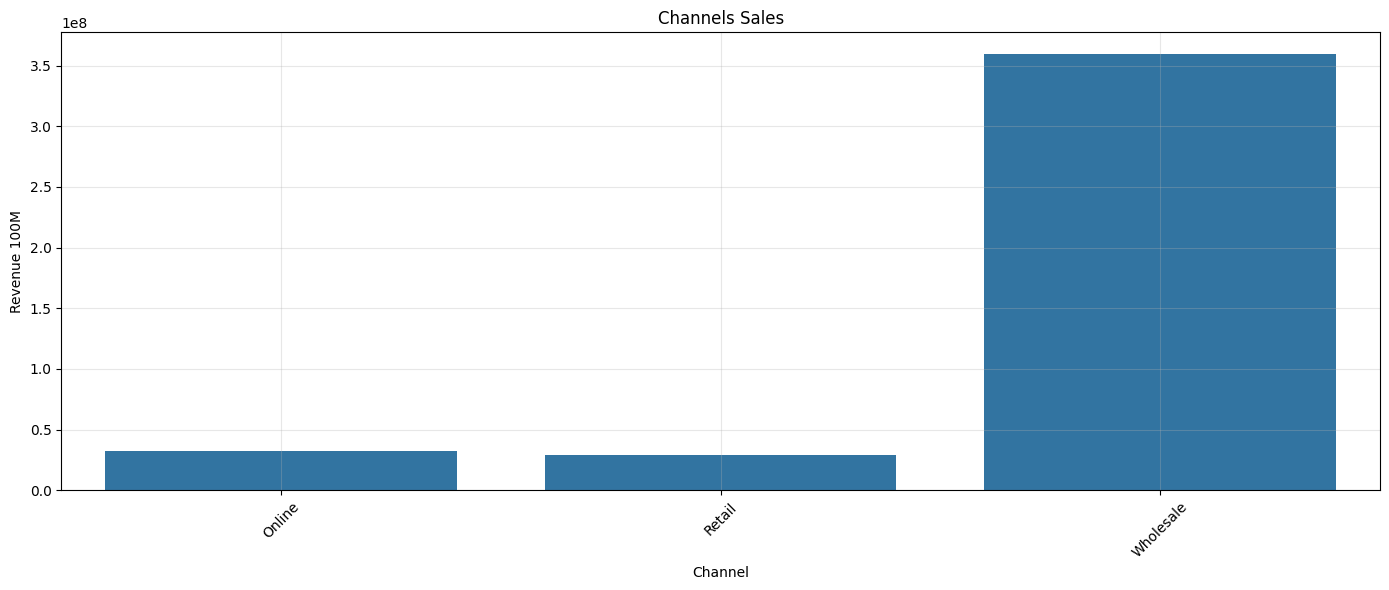

In [39]:
plt.figure(figsize=(14, 6))

sns.barplot(
    x=customer_type_sales["Channel"],
    y=customer_type_sales["Net_Sales"],
)

plt.title("Channels Sales")
plt.xlabel("Channel")
plt.ylabel("Revenue 100M")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

In [46]:
Sales[['Discount_Pct','Net_Sales_EGP']]

,Discount_Pct,Net_Sales_EGP
0,0.15,329.80
1,0.20,231.20
2,0.32,4814.40
3,0.32,11358.72
4,0.20,239.20
...,...,...
179995,0.20,278.40
179996,0.00,388.00
179997,0.00,776.00
179998,0.00,776.00


In [48]:
Sales['Discount_Pct'].value_counts()

Discount_Pct
0.00    53862
0.10    24867
0.05    20403
0.15    16503
0.20    13405
0.32     9380
0.28     9369
0.35     9363
0.38     9335
0.30     9225
0.25     4288
Name: count, dtype: int64

In [49]:
Discount_Pct_sales = (
    Sales.groupby("Discount_Pct")
    .agg(
        Total_Units=("Quantity", "sum"),
        Gross_Sales=("Gross_Sales_EGP", "sum"),
        Net_Sales=("Net_Sales_EGP", "sum"),
        Gross_Profit=("Gross_Profit_EGP", "sum"),
        Number_of_Invoices=("Invoice_ID", "nunique")
        
    )
    .reset_index()
)

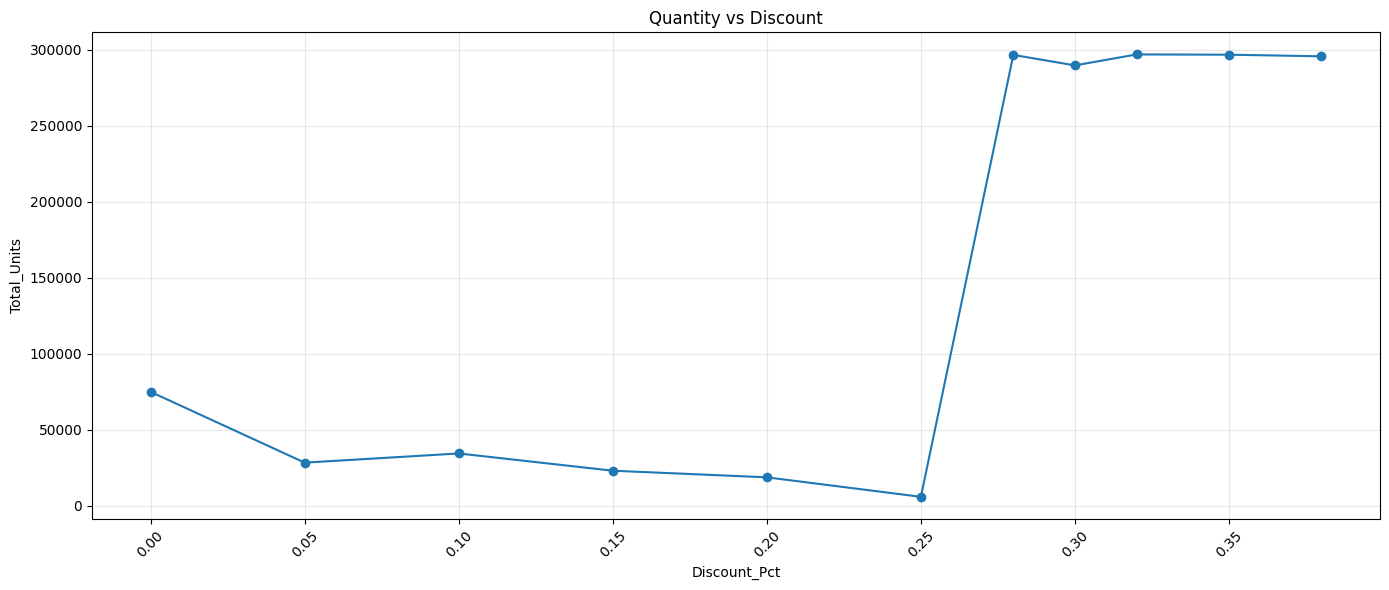

In [54]:
plt.figure(figsize=(14, 6))

plt.plot(
    Discount_Pct_sales["Discount_Pct"],
    Discount_Pct_sales["Total_Units"],
    marker="o"
)

plt.title("Quantity vs Discount")
plt.xlabel("Discount_Pct")
plt.ylabel("Total_Units")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

In [62]:
Sales['Channel'].value_counts()

Channel
Online       71559
Retail       61769
Wholesale    46672
Name: count, dtype: int64

In [66]:
Sales['Payment_Method'].value_counts()

Payment_Method
Cash             64622
Card             46478
Bank Transfer    45475
Wallet           23425
Name: count, dtype: int64

In [67]:
Payment_Method_sales = (
    Sales.groupby("Payment_Method")
    .agg(
        Total_Units=("Quantity", "sum"),
        Gross_Sales=("Gross_Sales_EGP", "sum"),
        Net_Sales=("Net_Sales_EGP", "sum"),
        Gross_Profit=("Gross_Profit_EGP", "sum"),
        Number_of_Invoices=("Invoice_ID", "nunique")
        
    )
    .reset_index()
)

In [68]:
Payment_Method_sales

,Payment_Method,Total_Units,Gross_Sales,Net_Sales,Gross_Profit,Number_of_Invoices
0,Bank Transfer,1117404,404109377,2.737117e+08,33701506.82,45475
1,Card,134908,48680797,3.838735e+07,9422925.22,46478
2,Cash,348068,125539966,9.172232e+07,17177455.18,64622
3,Wallet,60209,21761921,1.751696e+07,4586402.68,23425


([<matplotlib.patches.Wedge at 0x1fc92b70ef0>,
 [Text(-0.49823285518961646, 0.9806956826710327, 'Bank Transfer'),
  Text(-0.3714503785547695, -1.0353862159945526, 'Card'),
  Text(0.644207483263079, -0.8916258848350299, 'Cash'),
  Text(1.09063078562838, -0.14326370593986038, 'Wallet')],
 [Text(-0.2717633755579726, 0.5349249178205632, '65%'),
  Text(-0.2026092973935106, -0.5647561178152105, '9%'),
  Text(0.3513858999616794, -0.48634139172819807, '22%'),
  Text(0.5948895194336618, -0.0781438396035602, '4%')])

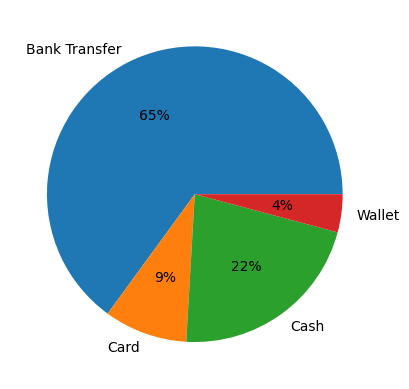

In [72]:
plt.pie(x=Payment_Method_sales['Net_Sales'], labels = Payment_Method_sales['Payment_Method'], autopct='%.0f%%')

In [73]:
Product_sales = (
    Sales.groupby("Product_Name")
    .agg(
        Total_Units=("Quantity", "sum"),
        Gross_Sales=("Gross_Sales_EGP", "sum"),
        Net_Sales=("Net_Sales_EGP", "sum"),
        Gross_Profit=("Gross_Profit_EGP", "sum"),
        
    )
    .reset_index()
)

In [74]:
Product_sales

,Product_Name,Total_Units,Gross_Sales,Net_Sales,Gross_Profit
0,BATGIRL - بيجامة حريمي صيفي2024,35480,13766240,9661002.12,1950541.80
1,Boys' Autumn Pajamas-Jurassic Park,20031,5788959,4061562.65,912043.71
2,Boys' Autumn Pajamas-Loony Tunes,17716,5119924,3611436.48,638305.08
3,Boys' Autumn Pajamas-Mickey Mouse,40621,11739469,8264475.20,1630530.13
4,Boys' Autumn Pajamas-Spider Man,38770,11204530,7868773.51,840713.71
5,Boys' pajamas -Don't Even!,23539,6944005,4888866.85,450753.95
6,Boys' pajamas -Mickey Mouse,17945,5293775,3725230.50,888202.63
7,Boys' summer pajamas- Seeds OF,13997,4185103,2934661.08,763603.62
8,Boys' summer pajamas-Bluey,12082,3612518,2538814.98,447781.91
9,Boys' summer pajamas-Mickey,33684,10071516,7095129.47,824612.80


In [79]:
top_products_qnty = Product_sales.sort_values(by=['Total_Units'], ascending=False).head()

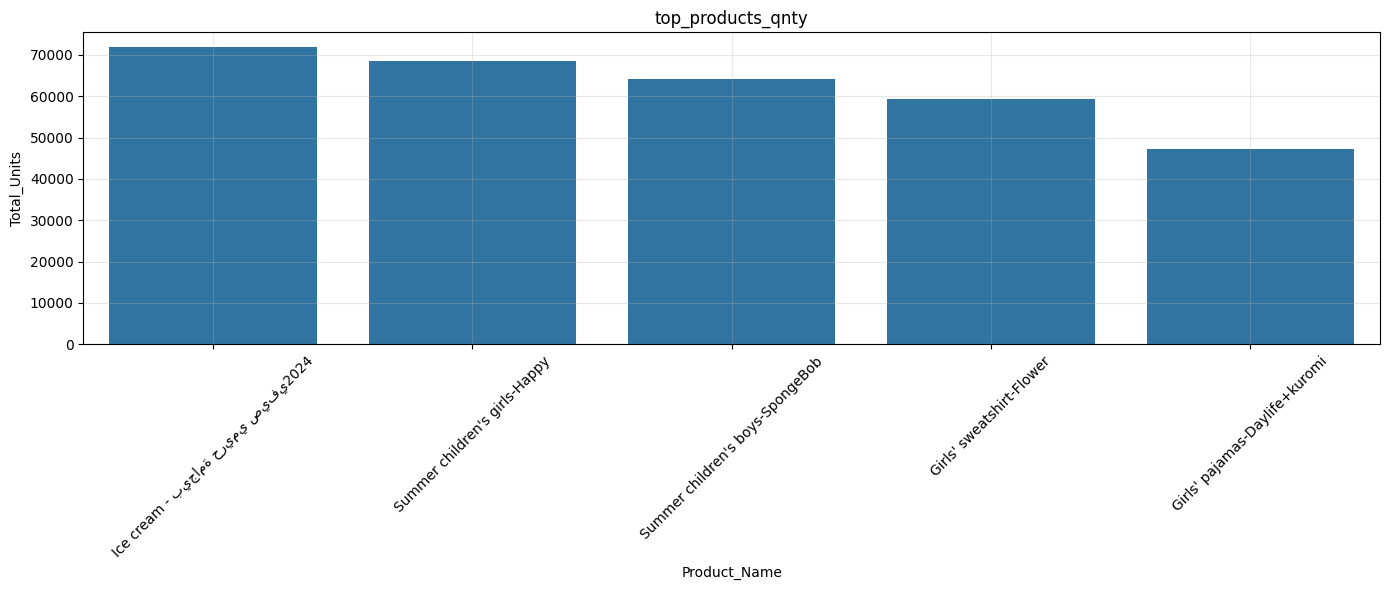

In [81]:
plt.figure(figsize=(14, 6))

sns.barplot(
    x=top_products_qnty["Product_Name"],
    y=top_products_qnty["Total_Units"],
)

plt.title("top_products_qnty")
plt.xlabel("Product_Name")
plt.ylabel("Total_Units")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

In [80]:
top_products_reveneu = Product_sales.sort_values(by=['Net_Sales'], ascending=False).head()

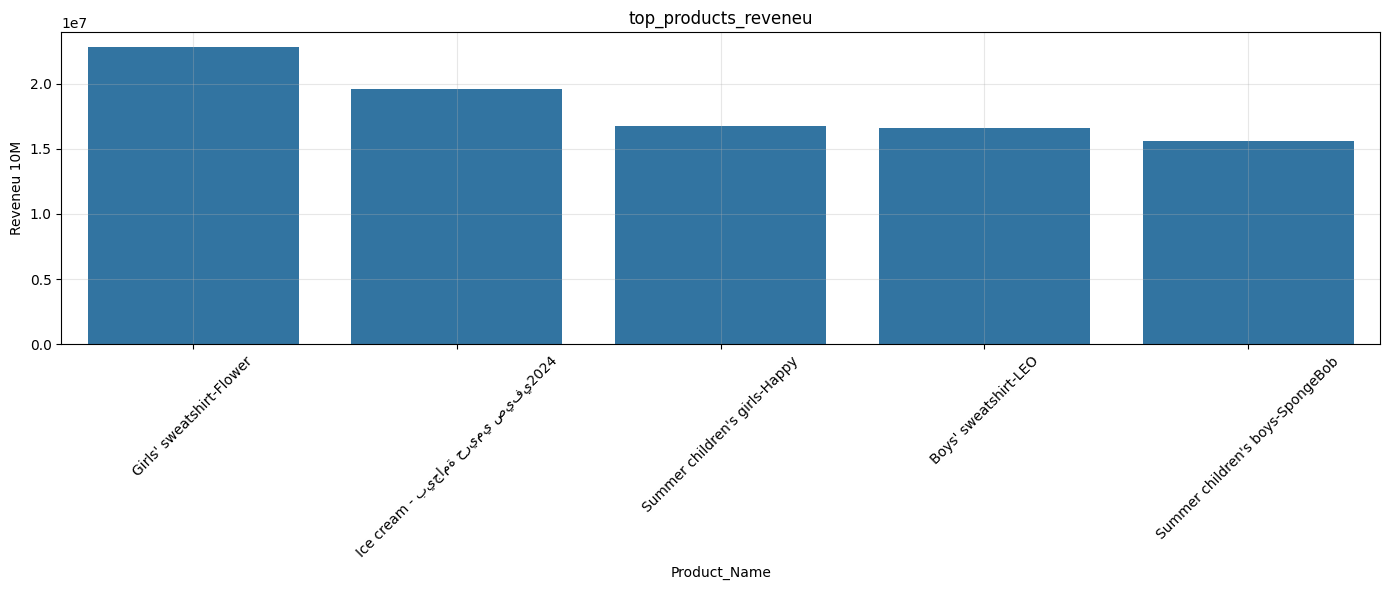

In [87]:
plt.figure(figsize=(14, 6))

sns.barplot(
    x=top_products_reveneu["Product_Name"],
    y=top_products_reveneu["Net_Sales"],
)

plt.title("top_products_reveneu")
plt.xlabel("Product_Name")
plt.ylabel("Reveneu 10M")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

In [88]:
Return_Reason_Value = (
    Sales.groupby("Return_Reason")
    .agg(
        Total_Units=("Quantity", "sum"),
        Refund_Value=("Refund_Value_EGP", "sum")
        
    )
    .reset_index()
)

In [92]:
Return_Reason_Value

,Return_Reason,Total_Units,Refund_Value
0,Changed mind,5940,1471459.43
1,Color / appearance,4226,1079630.75
2,Delivery issue,3289,853424.65
3,Fabric / stitching,6031,1509735.16
5,Print issue,3848,1000164.05
6,Size / fit,13899,3512591.51


In [91]:
Return_Reason_Value.drop([4], inplace=True)

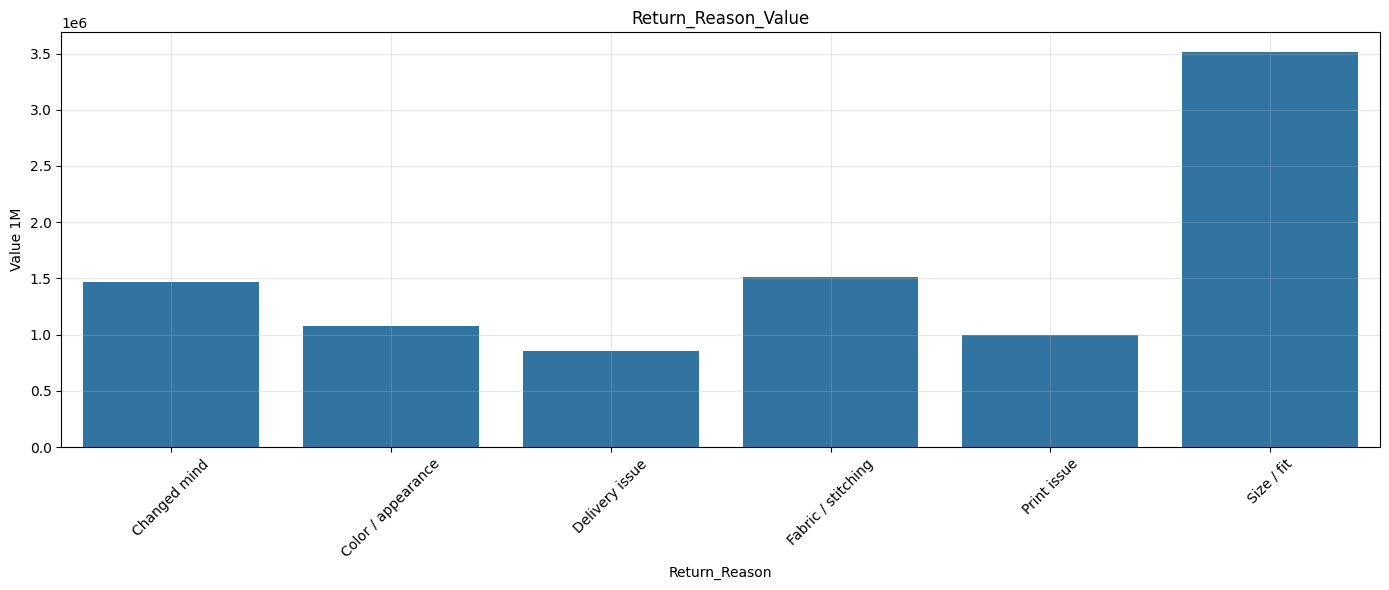

In [94]:
plt.figure(figsize=(14, 6))

sns.barplot(
    x=Return_Reason_Value["Return_Reason"],
    y=Return_Reason_Value["Refund_Value"],
)

plt.title("Return_Reason_Value")
plt.xlabel("Return_Reason")
plt.ylabel("Value 1M")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

In [95]:
customer_type_sales

,Channel,Total_Units,Gross_Sales,Net_Sales,Gross_Profit,Number_of_Invoices
0,Online,99339,35766917,3.262957e+07,11384070.74,71559
1,Retail,86174,31094146,2.934769e+07,10869176.78,61769
2,Wholesale,1475076,533230998,3.593611e+08,42635042.38,46672


In [105]:
print("Online gross margin=",11384070.74 / 3.262957e+07)

Online gross margin= 0.34888816309868625


In [104]:
print("Retail gross margin=",10869176.78 / 2.934769e+07)

Retail gross margin= 0.37035885209364006


In [103]:
print("Wholesale gross margin =",((42635042.38	 / 3.593611e+08)*100),'%')

Wholesale gross margin = 11.864122850247288 %


## Key EDA Finding

- During the exploratory data analysis (EDA), I identified that the dataset represents multiple business models rather than a single, unified business operation. These include B2B wholesale, B2C retail, and online sales, each with distinct sales patterns, revenue structures, and profitability metrics.
- Aggregating all transactions into a single set of KPIs can obscure the actual performance of individual business units. Each business model requires a separate view of its key performance indicators (KPIs), including total sales, sales volume, gross profit, and gross profit margin, to accurately evaluate its contribution to the overall business.

## Proposed Solution

- This finding highlights the need for a dynamic, CEO-level dashboard that provides both a consolidated view of the group's performance and the ability to drill down into individual business models. Such a dashboard would enable executives to compare business unit performance, identify profitability gaps, monitor sales trends, and make more informed, data-driven strategic decisions.